# Plotting postprocessed data

Example of the analysis functions of `postprocessed_analysis.py` on the timestamp `1791789186`
(postprocessing folder, `compute_keywords=['static']`): 5 result files (one per grid, $N_t$ = 1501 ... 501 at fixed $T_{max}$),
each containing 12 temperatures.

| function | what it does |
|---|---|
| `detect_job_parameters` | which parameters vary inside a file (inner), differ between files (outer) or are constant |
| `plot_gap_vs_parameter` | $|\Delta|/T_c$ vs the inner parameter, one curve per file, legend = parameter that differs between files |
| `analyze_errors_vs_grid` | gap difference and normalization / FDT errors vs $dt$ (or $T_{max}$) with fitted exponents |
| `plot_green_function_rows` | $g^R(t=-1,t')$ and $g^K(t=-1,t')$, all components, real and imaginary |
| `plot_consistency_rows` | normalization and FDT error rows at $t=-1$ vs $t'$ with printed maxima |

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('/home/filip/Git_Code/')
sys.path.append('/home/filip/Documents/Research/Superconducting_vortices/Keldysh-non-eq/psBQP-keldysh/')

from demler_tools.file_manager import path_management

import postprocessed_analysis as pa

In [2]:
# Initialize demler_tools path management
path_management.initialize(project_name='psBQP-keldysh')

timestamp = '1791789186'

Successfully initialized path management with following parameters:
     username:                fmarijanovic
     project name:            psBQP-keldysh
     controlling machine:     laptop
     library version:         v2.3.0-beta-8-g6d57f9e
     auto SSH transfer:       True
     default save location:   /home/filip/Documents/Research/data_files/
     LTS mount point:         /home/filip
     email domain:            phys.ethz.ch
     cluster OS:              Ubuntu
     cluster partition:       work
     SSH host file:           /home/filip/.ssh/known_hosts
     SSH key file:            /home/filip/.ssh/id_ed25519_euler
     default modules:         {'CentOS': 'gcc/8.2.0 python/3.11.2', 'Ubuntu': 'stack/2024-06 python/3.11.6'}


## Which parameters differ between the jobs?

In [3]:
detection = pa.detect_job_parameters(timestamp)

Timestamp 1791789186: 5 result file(s), indices [0, 1, 2, 3, 4]
  varies inside each file (inner): temperature
  differs between files (outer):
    dt: 0.020944, 0.0251327, 0.0314159, 0.0418879, 0.0628319
    time_sampling: 1501, 1251, 1001, 751, 501
  constant: critical_temperature = 1, eta = 0.2, time_duration = 31.4159


## Gap vs parameter (one curve per file, legend = parameter that differs between the files)

Timestamp 1791789186: 5 result file(s), indices [0, 1, 2, 3, 4]
  varies inside each file (inner): temperature
  differs between files (outer):
    dt: 0.020944, 0.0251327, 0.0314159, 0.0418879, 0.0628319
    time_sampling: 1501, 1251, 1001, 751, 501
  constant: critical_temperature = 1, eta = 0.2, time_duration = 31.4159
  file 2: 1 NaN gap value(s) at $T/T_c$ = 1 (not plotted)
  file 3: 1 NaN gap value(s) at $T/T_c$ = 1 (not plotted)
  file 4: 1 NaN gap value(s) at $T/T_c$ = 1 (not plotted)


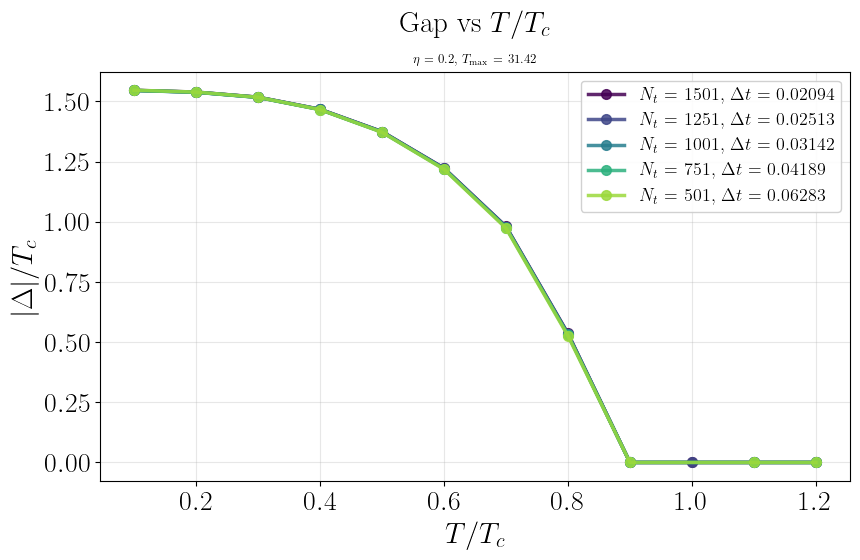

['$N_t$ = 1501, $\\Delta t$ = 0.02094', '$N_t$ = 1251, $\\Delta t$ = 0.02513', '$N_t$ = 1001, $\\Delta t$ = 0.03142', '$N_t$ = 751, $\\Delta t$ = 0.04189', '$N_t$ = 501, $\\Delta t$ = 0.06283']


In [4]:
result = pa.plot_gap_vs_parameter(timestamp, save_plot=False)
print(result['labels'])

## Error analysis with $dt$

Gap difference to the finest grid, $g^R$ / $g^K$ normalization and FDT error at $(t,t')=(-1,-1)$ vs $dt$ for every temperature,
with the fitted exponents $p$ in error $\propto dt^p$. The $g^R$ normalization error is exactly zero at $(-1,-1)$ by construction, see the
profile plots below for the error along $t'$.

Timestamp 1791789186: 5 result file(s), indices [0, 1, 2, 3, 4]
  varies inside each file (inner): temperature
  differs between files (outer):
    dt: 0.020944, 0.0251327, 0.0314159, 0.0418879, 0.0628319
    time_sampling: 1501, 1251, 1001, 751, 501
  constant: critical_temperature = 1, eta = 0.2, time_duration = 31.4159


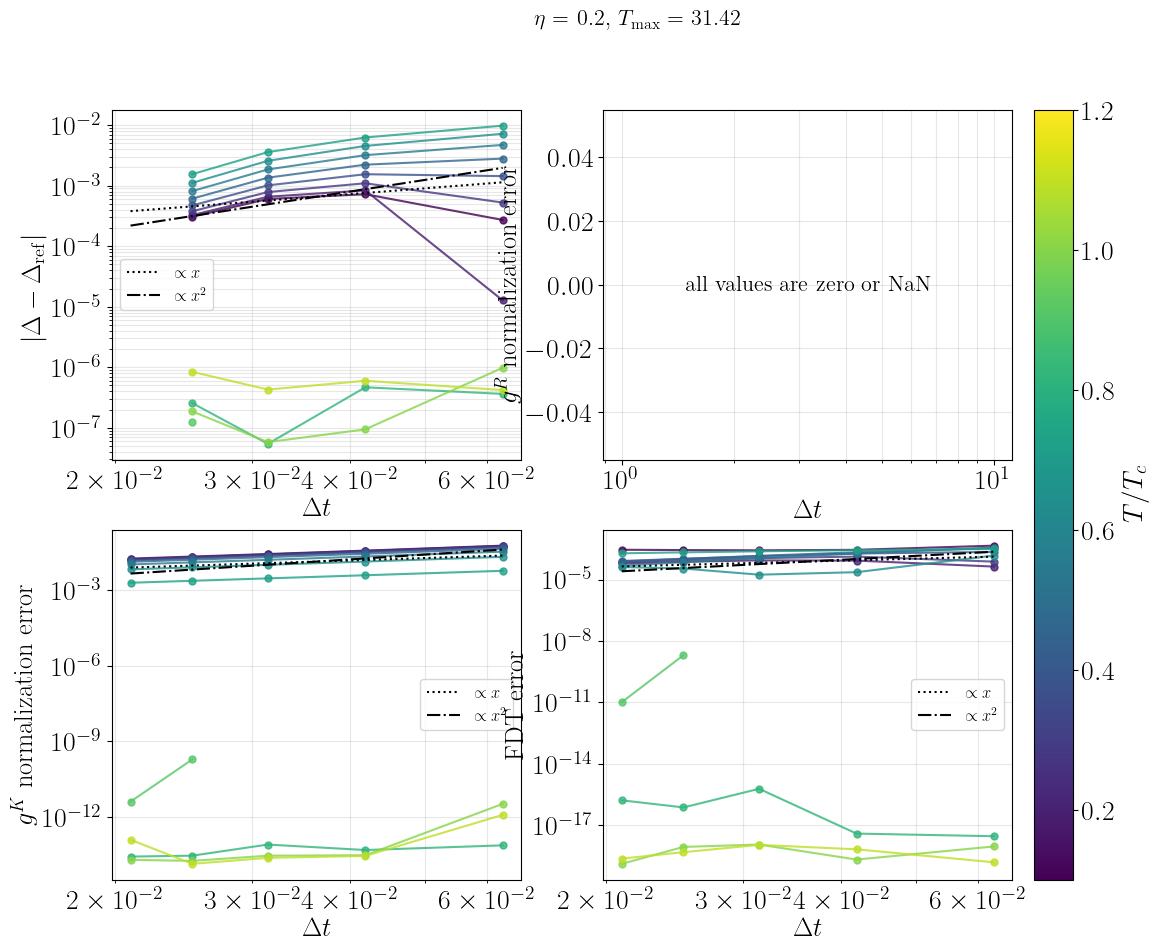

Fitted exponents p of error ~ dt^p (reference file index 0, dt = 0.02094, 0.02513, 0.03142, 0.04189, 0.06283)
   temperature |    gap_difference |  gr_normalization |  gk_normalization |               fdt
           0.1 |             -0.23 |               nan |              1.08 |              0.40
           0.2 |             -3.56 |               nan |              1.10 |             -0.31
           0.3 |              0.28 |               nan |              1.10 |              0.09
           0.4 |              1.14 |               nan |              1.09 |              0.94
           0.5 |              1.58 |               nan |              1.08 |              1.38
           0.6 |              1.84 |               nan |              1.06 |              1.84
           0.7 |              1.96 |               nan |              1.04 |              1.04
           0.8 |              1.93 |               nan |              0.99 |              0.44
           0.9 |              1.13 

In [5]:
errors = pa.analyze_errors_vs_grid(timestamp, save_plot=False)

## $g(t=-1,t')$ rows

The rows are saved by the `'static'` postprocessing (key `'rows'`). For older folders (like this one) the raw evolution run is used if it is
available locally; otherwise a message says what to copy or re-run. `directory_job_index` selects the file (grid), `job_index` the
temperature inside it.

In [6]:
try:
    rows = pa.plot_green_function_rows(timestamp, directory_job_index=0, job_index=0, save_plot=False)
except FileNotFoundError as error:
    print(error)

No rows stored in postprocessed folder 1791789186 (file 0) and the raw run 1791735275 is not available locally (expected /home/filip/Documents/Research/data_files/psBQP-keldysh/simulation_results/1791735275). Either copy the raw folder from the cluster or re-run the 'static' postprocessing, which now saves the rows. (Kwargs file not found for timestamp 1791735275)


## Normalization and FDT errors at $t=-1$ vs $t'$ (maximal errors are printed)

In [7]:
try:
    rows = pa.plot_consistency_rows(timestamp, directory_job_index=0, job_index=0, save_plot=False)
except FileNotFoundError as error:
    print(error)

No rows stored in postprocessed folder 1791789186 (file 0) and the raw run 1791735275 is not available locally (expected /home/filip/Documents/Research/data_files/psBQP-keldysh/simulation_results/1791735275). Either copy the raw folder from the cluster or re-run the 'static' postprocessing, which now saves the rows. (Kwargs file not found for timestamp 1791735275)


### Getting the rows for this timestamp

Either copy the raw folders listed in the `calculation_arguments` of the postprocessing folder from the cluster to the local data folder, or
re-run the `'static'` postprocessing on the cluster (the rows are now saved by default).